# Retail Outlet Performance — Data Preprocessing & EDA

## Programming for Business Analytics Group Mini Project

This notebook performs data preprocessing and exploratory data analysis on the Retail Outlet dataset. 

The purpose is to identify data quality issues, clean the dataset, handle missing values according to the project requirements, and prepare the data for further analysis.

### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Importing the Dataset

In [2]:
df = pd.read_csv("Retail_Outlets_Dataset.csv")

In [3]:
df.head()

,outlet id,region,Outlet Type,rent_cost,Staff Cost,inventory cost,operating_cost,marketing spend,Monthly_Revenue,profit margin
0,OUT-0125,western,supermarket,171.0,240.0,384.0,795.0,57.0,2388.0,0.6432
1,OUT-1122,north western,Convenience,155.0,260.0,290.0,705.0,106.0,2401.0,0.6622
2,OUT-0604,Western,Convenience,318.0,453.0,623.0,1394.0,201.0,3949.0,0.5961
3,OUT-0202,sabaragamuwa,CONVENIENCE,372.0,546.0,853.0,1771.0,201.0,4748.0,0.5847
4,OUT-0601,southern,Supermarket,219.0,NaN,517.0,1112.0,132.0,3553.0,0.6499


### Initial Dateset Inspection

In [4]:
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())

(1245, 10)
Index(['outlet id', 'region ', 'Outlet Type', 'rent_cost', 'Staff Cost',
       'inventory cost', 'operating_cost', 'marketing spend',
       'Monthly_Revenue', 'profit margin'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1245 entries, 0 to 1244
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   outlet id        1245 non-null   object 
 1   region           1222 non-null   object 
 2   Outlet Type      1245 non-null   object 
 3   rent_cost        1220 non-null   float64
 4   Staff Cost       1218 non-null   float64
 5   inventory cost   1218 non-null   float64
 6   operating_cost   1185 non-null   float64
 7   marketing spend  1217 non-null   float64
 8   Monthly_Revenue  1224 non-null   float64
 9   profit margin    1171 non-null   float64
dtypes: float64(7), object(3)
memory usage: 97.4+ KB
None
         rent_cost   Staff Cost  inventory cost  operating_cost  \
coun

- Shape shows rows and columns.  
- Columns shows variable names.  
- Info shows data types and missing values.  
- Describe gives summary statistics for numeric columns.

### Checking Data Quality Issues

In [5]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.nunique())
print(df["region "].unique())
print(df["Outlet Type"].unique())

outlet id           0
region             23
Outlet Type         0
rent_cost          25
Staff Cost         27
inventory cost     27
operating_cost     60
marketing spend    28
Monthly_Revenue    21
profit margin      74
dtype: int64
45
outlet id          1200
region               20
Outlet Type          12
rent_cost           293
Staff Cost          419
inventory cost      535
operating_cost      762
marketing spend     211
Monthly_Revenue    1013
profit margin       918
dtype: int64
['western' 'north western' ' Western' 'sabaragamuwa' ' southern'
 'NorthWestern' 'SABARAGAMUWA' 'SOUTHERN' 'Central' 'southern' 'Western'
 'WESTERN' 'Sabaragamuwa' 'central' nan 'Southern' 'CENTRAL'
 'North-Western' 'North Western' 'Central ' 'western ']
['supermarket' 'Convenience' 'CONVENIENCE' 'Supermarket' 'convenience'
 'SUPERMARKET' 'WHOLESALE' 'Conveniance' 'Super Market' 'Whole Sale'
 'Wholesale' 'wholesale']


The dataset is checked for common data quality problems before cleaning. This includes missing values, duplicate rows and inconsistent categorical values.

From the initial inspection, inconsistent capitalization, spacing and spelling can be seen in the Region and Outlet Type values.

### Renaming Columns

In [6]:
df.rename(columns={
    "outlet id":"Outlet_ID",
    "region ":"Region",
    "Outlet Type":"Outlet_Type",
    "rent_cost":"Rent_Cost",
    "Staff Cost":"Staff_Cost",
    "inventory cost":"Inventory_Cost",
    "operating_cost":"Operating_Cost",
    "marketing spend":"Marketing_Spend",
    "Monthly_Revenue":"Monthly_Revenue",
    "profit margin":"Profit_Margin"
}, inplace=True)

In [7]:
print(df.columns)

Index(['Outlet_ID', 'Region', 'Outlet_Type', 'Rent_Cost', 'Staff_Cost',
       'Inventory_Cost', 'Operating_Cost', 'Marketing_Spend',
       'Monthly_Revenue', 'Profit_Margin'],
      dtype='object')


We rename the columns to make the names consistent and easier to use in Python.

### Removing Duplicates

In [8]:
print(df.duplicated().sum())

45


In [9]:
df = df.drop_duplicates()

In [10]:
print(df.shape)

(1200, 10)


We drop duplicate rows to ensure each outlet record is unique.

### Standarizing Text Values

In [11]:
df["Region"] = df["Region"].str.strip().str.title()

In [12]:
print(df["Region"].unique())

['Western' 'North Western' 'Sabaragamuwa' 'Southern' 'Northwestern'
 'Central' nan 'North-Western']


In [13]:
df["Outlet_Type"] = df["Outlet_Type"].str.strip().str.title()

In [14]:
print(df["Outlet_Type"].unique())

['Supermarket' 'Convenience' 'Wholesale' 'Conveniance' 'Super Market'
 'Whole Sale']


The text values contain differences in capitalization, spaces and spelling. strip() removes unnecessary spaces at the beginning and end of values, while title() makes capitalization consistent.

### Fix Spelling anf Naming Differences

In [15]:
df["Region"] = df["Region"].replace({
    "Northwestern": "North Western",
    "North-Western": "North Western"
})

In [16]:
print(df["Region"].unique())

['Western' 'North Western' 'Sabaragamuwa' 'Southern' 'Central' nan]


In [17]:
df["Outlet_Type"] = df["Outlet_Type"].replace({ 
    "Conveniance": "Convenience", 
    "Super Market": "Supermarket", 
        "Whole Sale": "Wholesale"})

In [18]:
print(df["Outlet_Type"].unique())

['Supermarket' 'Convenience' 'Wholesale']


After removing spaces and standardizing capitalization, some values still represent the same category using different spelling or formatting. These values are changed to one consistent category name.

### Handling Missing Values

In [19]:
print(df.isnull().sum())

Outlet_ID           0
Region             22
Outlet_Type         0
Rent_Cost          25
Staff_Cost         24
Inventory_Cost     26
Operating_Cost     60
Marketing_Spend    25
Monthly_Revenue    20
Profit_Margin      72
dtype: int64


In [20]:
# Back-calculate missing Rent Cost
df["Rent_Cost"] = df["Rent_Cost"].fillna(
    df["Operating_Cost"] - df["Staff_Cost"] - df["Inventory_Cost"])

In [21]:
# Back-calculate Staff Cost
df["Staff_Cost"] = df["Staff_Cost"].fillna(
    df["Operating_Cost"] - df["Rent_Cost"] - df["Inventory_Cost"])

In [22]:
# Back-calculate Inventory Cost
df["Inventory_Cost"] = df["Inventory_Cost"].fillna(
    df["Operating_Cost"] - df["Rent_Cost"] - df["Staff_Cost"])

In [23]:
print(df.isnull().sum())

Outlet_ID           0
Region             22
Outlet_Type         0
Rent_Cost           0
Staff_Cost          0
Inventory_Cost      0
Operating_Cost     60
Marketing_Spend    25
Monthly_Revenue    20
Profit_Margin      72
dtype: int64


Some cost values were missing while the other cost values and Operating Cost were available. We calculated the missing cost using the relationship:

Operating Cost = Rent Cost + Staff Cost + Inventory Cost

This allows us to use the information already available in the same row instead of using an estimated value.

In [24]:
# Calculate Missing Operating Cost
df["Operating_Cost"] = df["Operating_Cost"].fillna(
    df["Rent_Cost"] + df["Staff_Cost"] + df["Inventory_Cost"])

In [25]:
print(df.isnull().sum())

Outlet_ID           0
Region             22
Outlet_Type         0
Rent_Cost           0
Staff_Cost          0
Inventory_Cost      0
Operating_Cost      0
Marketing_Spend    25
Monthly_Revenue    20
Profit_Margin      72
dtype: int64


Some Operating Cost values were missing. Since the three cost components are now available, we calculated Operating Cost using:

Operating Cost = Rent Cost + Staff Cost + Inventory Cost

This follows the formula given in the project instructions.

In [26]:
# Missing Marketing Spend
df["Marketing_Spend"] = df["Marketing_Spend"].fillna(
    df.groupby("Outlet_Type")["Marketing_Spend"].transform("median"))

In [27]:
print(df.groupby("Outlet_Type")["Marketing_Spend"].median())

Outlet_Type
Convenience    127.0
Supermarket    135.0
Wholesale      124.0
Name: Marketing_Spend, dtype: float64


In [28]:
print(df.isnull().sum())

Outlet_ID           0
Region             22
Outlet_Type         0
Rent_Cost           0
Staff_Cost          0
Inventory_Cost      0
Operating_Cost      0
Marketing_Spend     0
Monthly_Revenue    20
Profit_Margin      72
dtype: int64


In [29]:
# Monthly Revenue
df["Monthly_Revenue"] = df["Monthly_Revenue"].fillna(
    df.groupby("Outlet_Type")["Monthly_Revenue"].transform("median"))

In [30]:
print(df.isnull().sum())

Outlet_ID           0
Region             22
Outlet_Type         0
Rent_Cost           0
Staff_Cost          0
Inventory_Cost      0
Operating_Cost      0
Marketing_Spend     0
Monthly_Revenue     0
Profit_Margin      72
dtype: int64


In [31]:
# Calculating Missing Profit Margin
df["Profit_Margin"] = df["Profit_Margin"].fillna(
    (df["Monthly_Revenue"] - df["Operating_Cost"] - df["Marketing_Spend"])
    / df["Monthly_Revenue"])

In [32]:
print(df.isnull().sum())

Outlet_ID           0
Region             22
Outlet_Type         0
Rent_Cost           0
Staff_Cost          0
Inventory_Cost      0
Operating_Cost      0
Marketing_Spend     0
Monthly_Revenue     0
Profit_Margin       0
dtype: int64


In [33]:
# Handling Missing Region Values
df["Region"] = df["Region"].fillna("Unknown")

In [34]:
print(df["Region"].unique())

['Western' 'North Western' 'Sabaragamuwa' 'Southern' 'Central' 'Unknown']


There were 22 missing Region values. Since Region is a categorical variable and there was not enough information to determine the correct region, we labelled these values as "Unknown".

This keeps the records in the dataset without making up a region for an outlet.

### Data Checks

In [35]:
print(df.isnull().sum())

Outlet_ID          0
Region             0
Outlet_Type        0
Rent_Cost          0
Staff_Cost         0
Inventory_Cost     0
Operating_Cost     0
Marketing_Spend    0
Monthly_Revenue    0
Profit_Margin      0
dtype: int64


In [36]:
print(df.duplicated().sum())

0


In [37]:
print(df.shape)
print(df.columns)
print(df.dtypes)

(1200, 10)
Index(['Outlet_ID', 'Region', 'Outlet_Type', 'Rent_Cost', 'Staff_Cost',
       'Inventory_Cost', 'Operating_Cost', 'Marketing_Spend',
       'Monthly_Revenue', 'Profit_Margin'],
      dtype='object')
Outlet_ID           object
Region              object
Outlet_Type         object
Rent_Cost          float64
Staff_Cost         float64
Inventory_Cost     float64
Operating_Cost     float64
Marketing_Spend    float64
Monthly_Revenue    float64
Profit_Margin      float64
dtype: object


In [38]:
df.head()

,Outlet_ID,Region,Outlet_Type,Rent_Cost,Staff_Cost,Inventory_Cost,Operating_Cost,Marketing_Spend,Monthly_Revenue,Profit_Margin
0,OUT-0125,Western,Supermarket,171.0,240.0,384.0,795.0,57.0,2388.0,0.6432
1,OUT-1122,North Western,Convenience,155.0,260.0,290.0,705.0,106.0,2401.0,0.6622
2,OUT-0604,Western,Convenience,318.0,453.0,623.0,1394.0,201.0,3949.0,0.5961
3,OUT-0202,Sabaragamuwa,Convenience,372.0,546.0,853.0,1771.0,201.0,4748.0,0.5847
4,OUT-0601,Southern,Supermarket,219.0,376.0,517.0,1112.0,132.0,3553.0,0.6499


In [39]:
df = df[
    [
        "Outlet_ID",
        "Region",
        "Outlet_Type",
        "Rent_Cost",
        "Staff_Cost",
        "Inventory_Cost",
        "Operating_Cost",
        "Marketing_Spend",
        "Monthly_Revenue",
        "Profit_Margin"
    ]
]

In [40]:
print(df.columns)

Index(['Outlet_ID', 'Region', 'Outlet_Type', 'Rent_Cost', 'Staff_Cost',
       'Inventory_Cost', 'Operating_Cost', 'Marketing_Spend',
       'Monthly_Revenue', 'Profit_Margin'],
      dtype='object')


### Scaling Decision

We did not scale the numerical variables because the analysis uses the original business values, such as Monthly Revenue and Marketing Spend. Keeping the original units also makes the results easier to understand.


### Encoding Decision

Region and Outlet Type were kept as categorical text values. Encoding was not required during this preprocessing stage because the final regression predictor had not yet been selected.


### Final Checking

In [41]:
print(df.isnull().sum())

Outlet_ID          0
Region             0
Outlet_Type        0
Rent_Cost          0
Staff_Cost         0
Inventory_Cost     0
Operating_Cost     0
Marketing_Spend    0
Monthly_Revenue    0
Profit_Margin      0
dtype: int64


In [42]:
print(df.duplicated().sum())

0


In [43]:
print(df.shape)

(1200, 10)


In [44]:
df.head()

,Outlet_ID,Region,Outlet_Type,Rent_Cost,Staff_Cost,Inventory_Cost,Operating_Cost,Marketing_Spend,Monthly_Revenue,Profit_Margin
0,OUT-0125,Western,Supermarket,171.0,240.0,384.0,795.0,57.0,2388.0,0.6432
1,OUT-1122,North Western,Convenience,155.0,260.0,290.0,705.0,106.0,2401.0,0.6622
2,OUT-0604,Western,Convenience,318.0,453.0,623.0,1394.0,201.0,3949.0,0.5961
3,OUT-0202,Sabaragamuwa,Convenience,372.0,546.0,853.0,1771.0,201.0,4748.0,0.5847
4,OUT-0601,Southern,Supermarket,219.0,376.0,517.0,1112.0,132.0,3553.0,0.6499


### Export

In [45]:
df.to_csv("retail_outlets_clean.csv", index=False)

In [46]:
print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


The cleaned dataset was saved as retail_outlets_clean.csv.

This is the official cleaned dataset that will be used by the group for EDA and regression analysis.

# Retail Outlet Performance Analysis

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
df = pd.read_csv("retail_outlets_clean.csv")

df.head()

,Outlet_ID,Region,Outlet_Type,Rent_Cost,Staff_Cost,Inventory_Cost,Operating_Cost,Marketing_Spend,Monthly_Revenue,Profit_Margin
0,OUT-0125,Western,Supermarket,171.0,240.0,384.0,795.0,57.0,2388.0,0.6432
1,OUT-1122,North Western,Convenience,155.0,260.0,290.0,705.0,106.0,2401.0,0.6622
2,OUT-0604,Western,Convenience,318.0,453.0,623.0,1394.0,201.0,3949.0,0.5961
3,OUT-0202,Sabaragamuwa,Convenience,372.0,546.0,853.0,1771.0,201.0,4748.0,0.5847
4,OUT-0601,Southern,Supermarket,219.0,376.0,517.0,1112.0,132.0,3553.0,0.6499


In [49]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1200
Number of columns: 10


In [50]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Outlet_ID', 'Region', 'Outlet_Type', 'Rent_Cost', 'Staff_Cost', 'Inventory_Cost', 'Operating_Cost', 'Marketing_Spend', 'Monthly_Revenue', 'Profit_Margin']


In [51]:
print(df.dtypes)

Outlet_ID           object
Region              object
Outlet_Type         object
Rent_Cost          float64
Staff_Cost         float64
Inventory_Cost     float64
Operating_Cost     float64
Marketing_Spend    float64
Monthly_Revenue    float64
Profit_Margin      float64
dtype: object


In [52]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Numerical variables:")
print(list(numeric_cols))

Numerical variables:
['Rent_Cost', 'Staff_Cost', 'Inventory_Cost', 'Operating_Cost', 'Marketing_Spend', 'Monthly_Revenue', 'Profit_Margin']


In [53]:
df[numeric_cols].describe().round(2)

,Rent_Cost,Staff_Cost,Inventory_Cost,Operating_Cost,Marketing_Spend,Monthly_Revenue,Profit_Margin
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,244.83,385.27,538.34,1168.45,129.00,3067.74,0.56
std,76.45,118.04,170.59,358.19,49.02,1021.67,0.12
min,74.00,123.00,175.00,452.00,8.00,444.00,-1.04
25%,183.00,283.00,389.50,858.75,90.00,2267.75,0.52
50%,247.50,383.50,541.00,1166.00,130.00,3081.00,0.58
75%,309.00,486.25,685.00,1475.25,167.00,3850.50,0.62
max,404.00,644.00,903.00,1874.00,255.00,5662.00,0.78


## Histograms
Histograms are used to examine the distribution of each numerical variable. They help identify the typical range, spread, skewness and unusual observations.

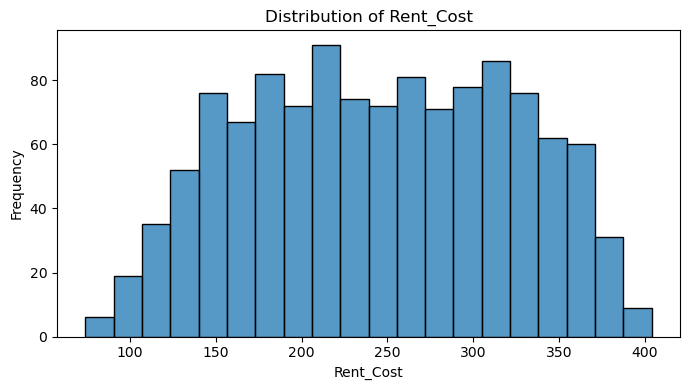

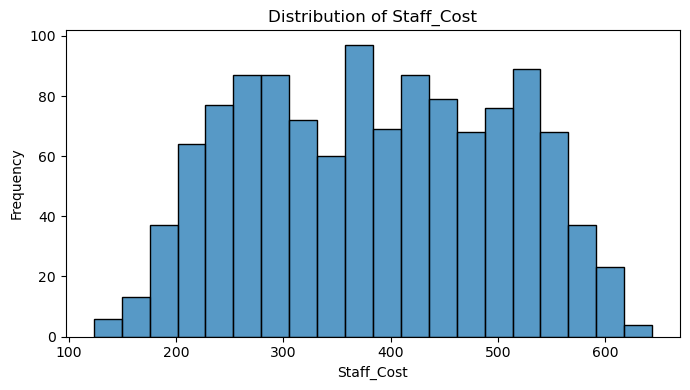

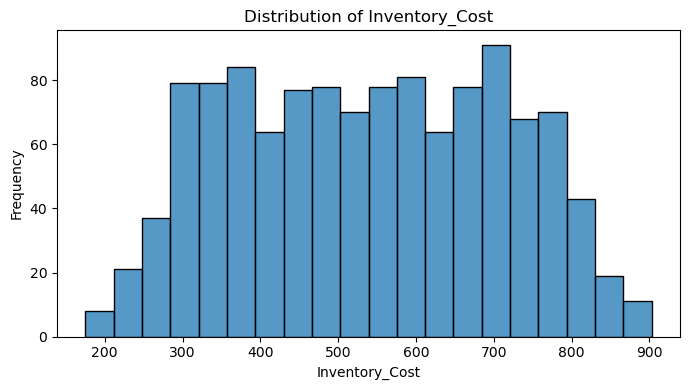

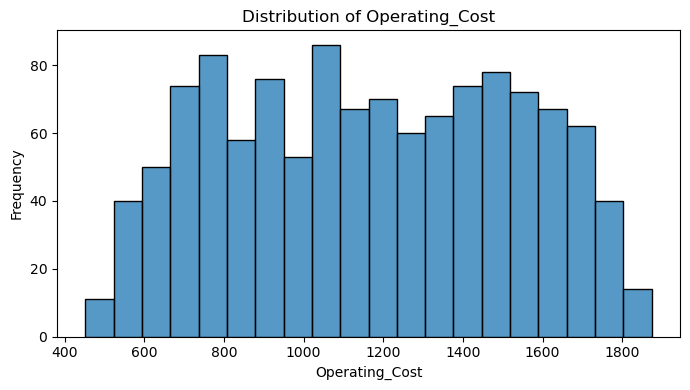

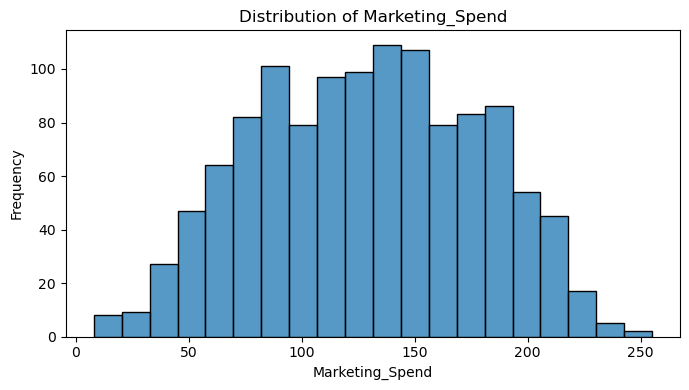

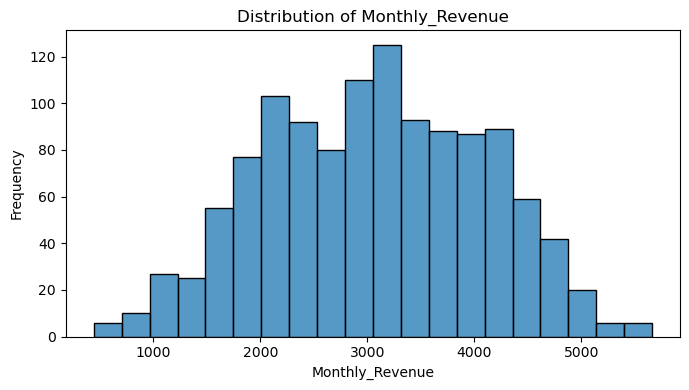

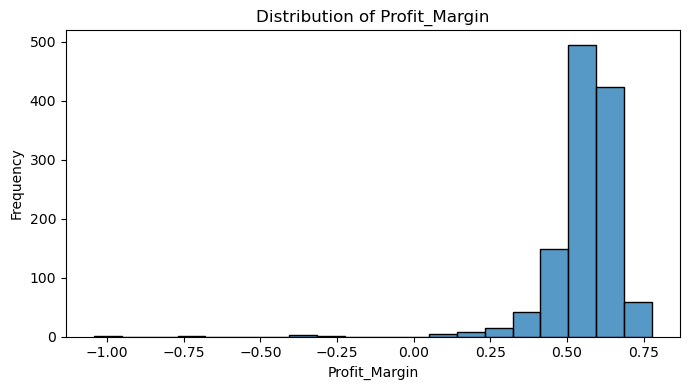

In [54]:
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        data=df,
        x=col,
        bins=20,
    )
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()

#### Histogram Findings

The histograms show that most cost and revenue variables are concentrated around their central values.

Rent Cost, Staff Cost, Inventory Cost, Operating Cost, Marketing Spend and Monthly Revenue show relatively balanced distributions.

Profit Margin shows a lower tail because a small number of outlets have low or negative profit margins.

Overall, the histograms provide an understanding of the spread and distribution of the numerical variables.

## Correlation Analysis

Correlation analysis is used to examine the strength and direction of linear relationships between the numerical variables.

The correlation coefficient ranges from -1 to +1. Positive values indicate a positive relationship, while negative values indicate a negative relationship.

In [56]:
correlation_matrix = df[numeric_cols].corr()

correlation_matrix.round(4)

,Rent_Cost,Staff_Cost,Inventory_Cost,Operating_Cost,Marketing_Spend,Monthly_Revenue,Profit_Margin
Rent_Cost,1.0000,0.9353,0.9375,0.9682,0.8491,0.8198,0.0140
Staff_Cost,0.9353,1.0000,0.9457,0.9796,0.8541,0.8306,0.0067
Inventory_Cost,0.9375,0.9457,1.0000,0.9880,0.8544,0.8320,0.0057
Operating_Cost,0.9682,0.9796,0.9880,1.0000,0.8696,0.8449,0.0079
Marketing_Spend,0.8491,0.8541,0.8544,0.8696,1.0000,0.9084,0.2594
Monthly_Revenue,0.8198,0.8306,0.8320,0.8449,0.9084,1.0000,0.4231
Profit_Margin,0.0140,0.0067,0.0057,0.0079,0.2594,0.4231,1.0000


#### Heatmap

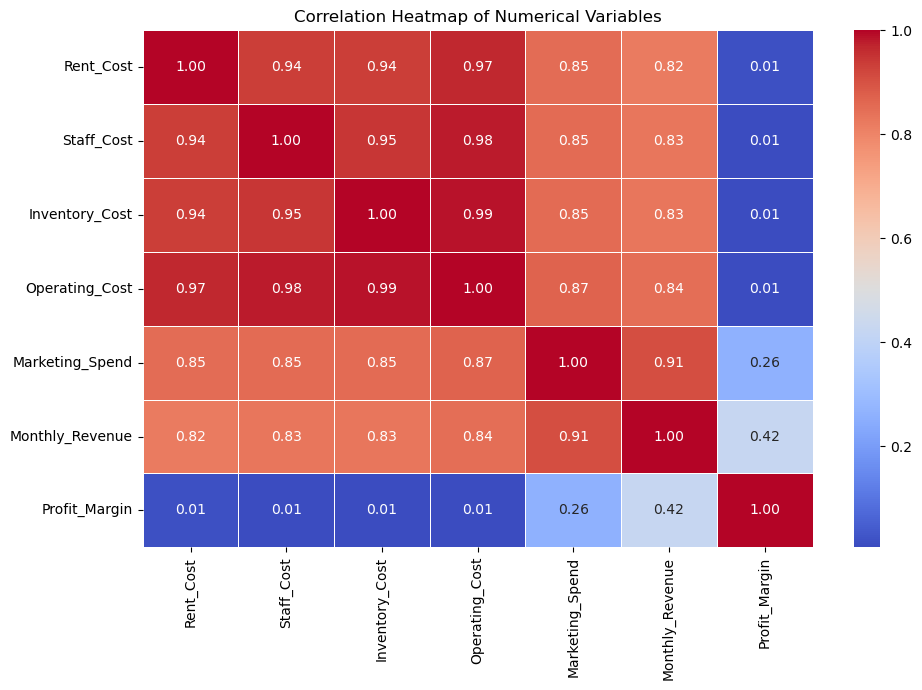

In [57]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

#### Correlation Heatmap Interpretation

The correlation heatmap shows the strength and direction of linear relationships between the numerical variables.

Marketing Spend has a very strong positive correlation with Monthly Revenue, with a correlation coefficient of approximately 0.91.

Monthly Revenue also has strong positive relationships with the different cost variables.

Operating Cost has very strong relationships with Rent Cost, Staff Cost and Inventory Cost. This is expected because Operating Cost is calculated using these three cost components.

The correlation results indicate associations between variables and do not by themselves prove causation.

## Marketing Spend and Monthly Revenue

The relationship between Marketing Spend and Monthly Revenue is investigated because marketing expenditure is relevant to retail sales performance and shows a strong relationship in the correlation analysis.

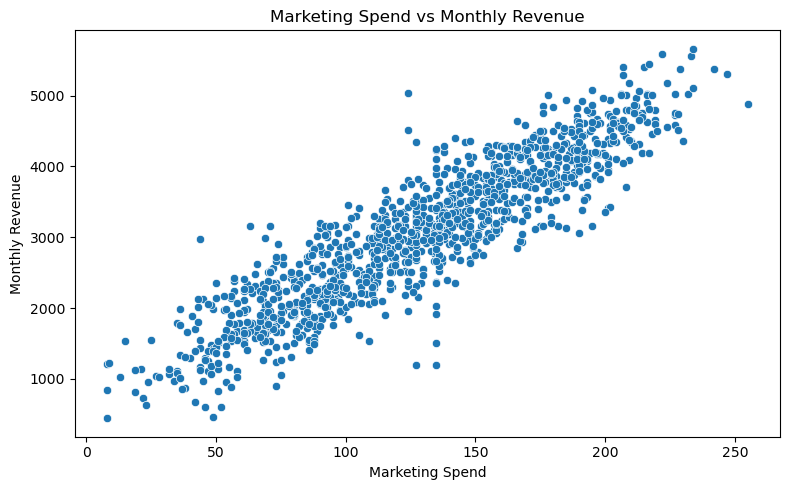

In [58]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Marketing_Spend",
    y="Monthly_Revenue"
)

plt.title("Marketing Spend vs Monthly Revenue")
plt.xlabel("Marketing Spend")
plt.ylabel("Monthly Revenue")

plt.tight_layout()
plt.show()

In [59]:
marketing_revenue_corr = df["Marketing_Spend"].corr(
    df["Monthly_Revenue"]
)

print(
    "Correlation between Marketing Spend and Monthly Revenue:",
    round(marketing_revenue_corr, 4)
)

Correlation between Marketing Spend and Monthly Revenue: 0.9084


#### Scatterplot Interpretation

The scatter plot shows a clear positive relationship between Marketing Spend and Monthly Revenue.

The correlation coefficient is approximately 0.9084, indicating a very strong positive linear association.

This means that retail outlets with higher marketing spending tend to have higher monthly revenue.

However, this relationship does not prove that higher marketing spending causes higher revenue, because other factors may also influence revenue.

## Selection of Dependent Variable

#### Dependent Variable: Monthly Revenue

Monthly Revenue was selected as the dependent variable because it directly represents the sales performance of a retail outlet.

The EDA shows that Monthly Revenue has strong relationships with several numerical variables, particularly Marketing Spend.

Therefore, Monthly Revenue is an appropriate target variable for the simple linear regression analysis.

## Selection of Independent Variable

#### Independent Variable: Marketing Spend

Marketing Spend was selected as the independent variable because it has a very strong positive relationship with Monthly Revenue.

The correlation coefficient between Marketing Spend and Monthly Revenue is approximately 0.9084.

Marketing Spend also has a logical business relationship with retail sales performance.

Therefore, Marketing Spend is selected as the single predictor for the simple linear regression.

## Key EDA Findings

1. Most numerical variables show relatively balanced distributions.

2. Profit Margin has a lower tail because a small number of outlets have low or negative profit margins.

3. Monthly Revenue has strong positive relationships with several operational and financial variables.

4. Marketing Spend has a very strong positive correlation with Monthly Revenue (r ≈ 0.91).

5. The scatter plot confirms a clear positive relationship between Marketing Spend and Monthly Revenue.

6. Operating Cost has strong relationships with its component costs, which is expected because it is calculated from Rent Cost, Staff Cost and Inventory Cost.

7. Monthly Revenue was selected as the dependent variable because it represents retail outlet sales performance.

8. Marketing Spend was selected as the independent variable because it has the strongest relevant relationship with Monthly Revenue and has a logical business connection with sales performance.

9. Correlation represents association and does not by itself establish causation.